[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_rollvar/BA_L4_rollvar.ipynb)

# BA_L4_rollvar: Rolling VaR 1% of Stablecoin Peg Deviations

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Value-at-risk at the 1% level of the daily close deviation from the 1 USD peg of USDT, USDC and DAI, over a rolling window of 365 days, January 2022 to 23 October 2026. Data: EODHD daily aggregated prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

The value-at-risk at level 1%, VaR 1% $= -q_{0.01}$, of the daily close deviation $d_t = 10^4\,(P_t - 1)$ in basis points (bp), computed over the previous 365 days and written as a positive loss.
With 365 days the 1% quantile lies between the 4th and 5th lowest close, so the line moves in steps when single days enter or leave the window.

**Data:** EOD Historical Data (EODHD) daily prices, 1 January 2021 to 23 October 2026 (the first window ends on 1 January 2022).

In [5]:
END = '2026-10-23'                      # last day of the lecture sample


def ohlc(sym, start=None, end=END):
    """Daily open, high, low and close from data/market/<sym>.csv."""
    x = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    return x.loc[start:end]


dv, lo = {}, {}
for s in ['USDT', 'USDC', 'DAI']:
    x = ohlc(f'{s}-USD.CC', '2021-01-01')
    dv[s], lo[s] = 1e4 * (x['close'] - 1), 1e4 * (x['low'] - 1)     # deviation of the close and of the intraday low, bp
dv, lo = pd.DataFrame(dv), pd.DataFrame(lo)
print(f'daily closes from {dv.index[0].date()} to {dv.index[-1].date()}: {len(dv)} days')

daily closes from 2021-01-01 to 2026-10-23: 2122 days


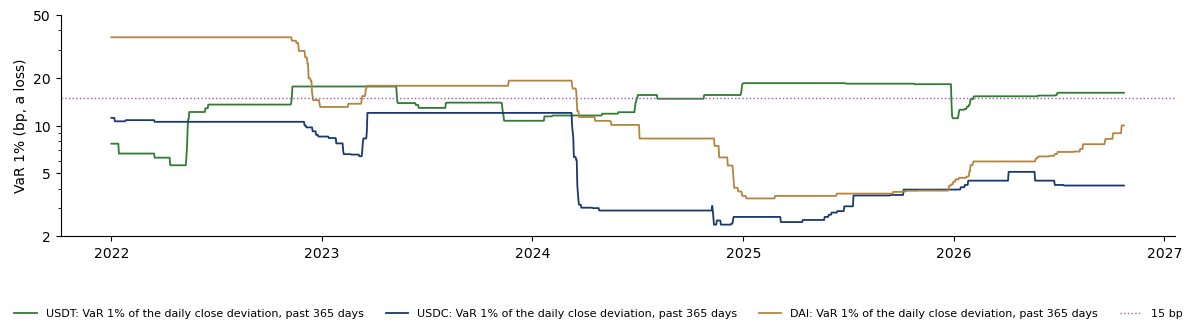

In [6]:
var365 = (-dv.rolling(365).quantile(0.01)).loc['2022-01-01':]
fig, ax = plt.subplots(figsize=(12, 3.3))
for s in dv:
    ax.plot(var365.index, var365[s], color=COL[s], lw=1.3, label=f'{s}: VaR 1% of the daily close deviation, past 365 days')
ax.axhline(15, color=ETH, ls=':', lw=1, label='15 bp')
ax.set_ylabel('VaR 1% (bp, a loss)'); ax.set_yscale('log'); ax.set_ylim(2, 50); ax.set_yticks([2, 5, 10, 20, 50])
ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
save(fig, 'ba_l4_rollvar', 0.15, ncol=4)

## Key numbers

In [7]:
print('VaR 1% over the full sample 2021-2026 (bp):', (-dv.quantile(0.01)).round(1).to_dict())
pd.DataFrame({'lowest': var365.min(), 'date of lowest': var365.idxmin().dt.date, 'highest': var365.max(),
              'date of highest': var365.idxmax().dt.date, 'on 23 Oct 2026': var365.iloc[-1]}).round(1)

VaR 1% over the full sample 2021-2026 (bp): {'USDT': 15.5, 'USDC': 7.6, 'DAI': 17.2}


,lowest,date of lowest,highest,date of highest,on 23 Oct 2026
USDT,5.6,2022-04-13,18.6,2025-01-01,16.2
USDC,2.4,2024-11-11,12.0,2023-03-21,4.2
DAI,3.5,2025-01-06,36.2,2022-01-01,10.0


**How to read it:** USDT is the only coin whose tail widened, from 5.6 bp (April 2022) to 18.6 bp (1 January 2025) and 16.2 bp on 23 October 2026.
USDC stayed at 12.0 bp for a year after SVB and is at 4.2 bp now; DAI fell from 36.2 bp at the start of 2022 to 3.5 bp in January 2025 and is at 10.0 bp now.